# 12 — The two analysis samples (Stage 2)

Stage 2 of `docs/real_data_roadmap.md`: turn the raw tables audited in notebook 11 into the two lists
the estimator will read.

- **Density tracer (T):** one row per Tempel group, with one center and one radius.
- **Velocity tracer:** one row per CF4 group that passes the cuts, with one peculiar velocity u.
- **Second density field (M, section 6):** the 2MRS galaxies Nusser used, with the CF4 groups inside
  the 2MRS mask as their velocity sample (advisor meeting 2026-10-14).

Every later stage reads only these two samples, so a group counted twice, or singletons merged into
one fake group, would corrupt everything downstream without any error.

**Decisions in force** (cut values in `dvcorr.config.SampleConfig`, rule 4):

| Choice | Value | Decided |
| --- | --- | --- |
| Primary richness cut | `Ng ≥ 1`: all groups **and** singletons | 2026-10-15 |
| Velocity u | EDD's `Vpec` ramp with the **natural log** restored | 2026-10-18 (notebook 11 §7, §13) |
| CF4 depth | **no cz cut**: every depth (Nusser's `Vcmb` < 10,000 km/s is a switchable variant) | 2026-10-18 |
| CF4 sky | inside the SDSS footprint: HEALPix nside-32 pixels holding a Tempel galaxy | roadmap |

**Thin consumer.** The samples are built by `dvcorr.pipeline.real_catalogs`
(`collapse_tempel_groups`, `select_tempel_tracers`, `select_cf4_velocities`, `duplicate_test`,
`sample_counts`; for 2MRS `select_twomrs_tracers`, `select_cf4_velocities_in_twomrs`,
`twomrs_duplicate_test`, `counts_matrix`). The figures come from `dvcorr.pipeline.real_catalog_audit`. Their docstrings are the
definition site.

In [1]:
%matplotlib inline

import pandas as pd

from dvcorr.config import SampleConfig
from dvcorr.pipeline import real_catalog_audit as audit
from dvcorr.pipeline.real_catalogs import (
    collapse_tempel_groups,
    counts_matrix,
    duplicate_test,
    footprint_pixels,
    load_cf4_groups,
    load_cf4_velocities,
    load_tempel_galaxies,
    load_twomrs_galaxies,
    sample_counts,
    select_cf4_velocities,
    select_cf4_velocities_in_twomrs,
    select_tempel_tracers,
    select_twomrs_tracers,
    twomrs_duplicate_test,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

config = SampleConfig()
tempel = load_tempel_galaxies()
velocities = load_cf4_velocities()
cf4_groups = load_cf4_groups()

tracers = select_tempel_tracers(collapse_tempel_groups(tempel), config)
pixels = footprint_pixels(tempel.table["RA"], tempel.table["DE"], config.footprint_nside)
cf4 = select_cf4_velocities(velocities, cf4_groups, pixels, config)
print(config)
print(f"Tempel density tracers: {len(tracers):,}    CF4 velocity tracers: {len(cf4.table):,}")

SampleConfig(velocity_cz_max=None, min_richness=1, footprint_nside=32, velocity_definition='vpec_ln')
Tempel density tracers: 179,681    CF4 velocity tracers: 26,302


## 1 — Tempel: one row per group

`collapse_tempel_groups` applies the three Tempel traps from notebook 11 §3:

- **Trap 1:** `IDg = 0` is shared by every isolated galaxy, so it is not an identity. Real groups are keyed
  by `IDg > 0`; each singleton is its own tracer, keyed by its galaxy `ID`.
- **Trap 2:** the center is the member with the **lowest `Rg` present**. That is `Rg = 1`, unless the
  clipped table dropped the brightest member (375 groups). Rows are grouped by `IDg`, never by row count,
  so the 402 groups with `Ng ≥ 2` left as a single row stay groups.
- **Trap 4:** the radius is `dc`, constant within every group (the function raises if it is not). `gVcmb`
  is not used. For the counts below, a group's redshift is `cz_cmb` = c × the mean member `zcmb`, which
  is the redshift `dc` encodes (to ~2 km/s wherever no member was clipped).

The first rows show each case. `IDg = 1` has `Ng = 7` but only one row left, its `Rg = 5` member:
it stays a group, centered on that member. The last rows are singletons.

*Verify yourself:* `tempel.table.query("IDg == 1")` has a single row with `Rg = 5`.

In [2]:
display(tracers.head(4))
display(tracers[tracers.is_singleton].head(3))
tracers.groupby("is_singleton").agg(tracers=("ID", "size"), median_Ng=("Ng", "median"),
                                    rows_present=("n_members", "sum"))

,IDg,ID,pgc,is_singleton,Ng,n_members,center_Rg,RA,DE,glon,glat,dc,cz_cmb
0,1,408210,4154791,False,7,1,5,121.9474,16.3940,206.1298,24.0735,438.29,29910.293535
1,5,7,4581691,False,19,19,1,163.4606,16.8498,227.5155,60.9578,371.96,25737.024734
2,14,19,1396685,False,15,15,1,206.0967,11.6491,344.2605,70.1471,416.22,28873.211492
3,15,21,140689,False,38,11,1,255.6770,34.0600,56.7866,36.3134,439.50,29644.023324


,IDg,ID,pgc,is_singleton,Ng,n_members,center_Rg,RA,DE,glon,glat,dc,cz_cmb
49671,0,5,1739055,True,1,1,1,242.5413,25.5061,42.5773,45.7316,321.77,22202.629439
49672,0,10,169917,True,1,1,1,210.6114,9.6390,350.0529,65.7826,368.76,25512.338176
49673,0,15,53822,True,1,1,1,226.1649,26.9771,40.3953,60.4268,137.54,9392.497709


,tracers,median_Ng,rows_present
is_singleton,,,
False,49671,2.0,175942
True,130010,1.0,130010


Every one of the 305,952 galaxy rows lands in exactly one tracer: 175,942 rows in groups plus 130,010
singletons. The `rows_present` column sums back to the table.

## 2 — CF4: the velocity sample

`select_cf4_velocities` joins the two CF4 files row by row (it raises if their `pgc` order differs). Then:

1. it applies **no cz cut** (the default since 2026-10-18; set `SampleConfig(velocity_cz_max=10_000.0)`
   for Nusser's depth, cut on the velocities file's `Vcmb`, from which `fV` and u are built);
2. it keeps groups inside the SDSS footprint, using the groups file's positions (the velocities file has
   pgc 51922 at the wrong position, notebook 11 §2);
3. it computes u = w·Vpds + (1 − w)·v_WF, with v_WF in the natural log and w = clip(1 − Vls/3000, 0, 1);
4. it **drops** any group whose u is undefined, rather than filling it (rule 5).

`sigma_u` is the eDM error of the ln velocity. The calibrator groups have eDM = 0 ("not given"), so
their `sigma_u` is NaN. They are kept: Nusser's weight w = 1 needs no error.

In [3]:
print(f"dropped for undefined u: {cf4.n_undefined_velocity}  (pgc {cf4.undefined_pgc})")
display(velocities.table[velocities.table.pgc.isin(cf4.undefined_pgc)][
    ["pgc", "Vcmb", "Vls", "fV", "DMzp", "eDM", "Vpds", "Vpwf", "Vpec"]])
cf4.table.describe().T[["count", "min", "50%", "max"]].round(1)

dropped for undefined u: 1  (pgc (39346,))


,pgc,Vcmb,Vls,fV,DMzp,eDM,Vpds,Vpwf,Vpec
6499,39346,0,94,0,28.17,0.0,-321,0,-311


,count,min,50%,max
pgc,26302.0,20919.0,1841407.0,9003288.0
RA,26302.0,109.9,185.2,262.7
DE,26302.0,-5.9,24.4,70.4
glon,26302.0,0.0,179.7,360.0
glat,26302.0,17.6,56.1,89.7
Vcmb,26302.0,-61.0,21120.0,31105.0
Vls,26302.0,-23.0,20889.5,30691.0
fV,26302.0,-61.0,22280.0,33593.0
DMzp,26302.0,24.3,37.3,39.6
eDM,26302.0,0.0,0.5,0.9


**The one dropped group** is pgc 39346: a calibrator (eDM = 0) at `Vcmb` = 0, about 4 Mpc away. At
fV = 0 the log in v_WF is undefined. EDD's published `Vpec` (−311) blends in the filler 0 that the file
writes there, with weight 0.03. That 0 is not a velocity, so the group is dropped. The group with
fV < 0 (pgc 2801026, `Vcmb` = −61) is kept with u = `Vpds`, as EDD's own rule does.

With no cz cut the sample runs over the whole CF4 depth inside SDSS: `Vcmb` from −61 to 31,105 km/s,
median 21,120. u is still centered near zero (median −85 km/s), but σ_u now runs from 5 km/s for the
nearest groups to 8,200 km/s at the far end, with a median of 4,430 km/s. Most of the sample is
noise-dominated: 21,822 of the 26,302 groups lie beyond 10,000 km/s, where Nusser stopped.

## 3 — The duplicate test

The methodological note (§6.2) requires one Tempel row per group identifier and one CF4 row per
identifier. `duplicate_test` checks four keys. The last Tempel row is the strongest: every tracer's
center galaxy `ID` is unique, so no galaxy centers two tracers.

In [4]:
dupes = duplicate_test(tracers, cf4)
display(dupes)
assert (dupes["duplicates"] == 0).all()

,rows,unique_keys,duplicates
key,,,
"Tempel groups, by IDg",49671,49671,0
"Tempel singletons, by ID",130010,130010,0
"Tempel tracers, by center ID",179681,179681,0
"CF4 groups, by pgc",26302,26302,0


## 4 — Counts against the roadmap

`sample_counts` gives both funnels. Neither sample is cut in depth: the density sample never is (it has
to reach past the deepest velocity center by the largest shell radius), and the CF4 sample has no cz cut
for now.

In [5]:
sample_counts(tracers, cf4, config)

,count
sample,
Tempel real groups (IDg > 0),49671
Tempel singletons (IDg = 0),130010
"Tempel density tracers, Ng >= 1",179681
Tempel groups centered on Rg > 1 (Trap 2 fallback),375
CF4 groups (files),38057
CF4 groups at all depths,38057
"CF4 groups at all depths, inside the SDSS footprint",26303
dropped: u undefined (vpec_ln),1
CF4 velocity sample,26302


| Roadmap *Expect (measured)* | Measured | Verdict |
| --- | --- | --- |
| 49,671 real groups | 49,671 | agrees |
| 130,010 singletons | 130,010 | agrees |
| 375 groups without `Rg = 1` (Stage 1) | 375 centered on Rg > 1 | agrees |
| CF4 groups inside the footprint, all depths | 26,303 before the velocity cut; **26,302** in the sample | one group dropped for undefined u |

**The cz < 10,000 counts are now a variant.** The roadmap's earlier numbers (4,481 CF4 groups in the
footprint; 6,367 groups and 15,278 singletons at cz < 10,000) belong to Nusser's depth, which is no longer
the primary sample. They are still checked in `tests/test_real_catalogs.py` with
`SampleConfig(velocity_cz_max=10_000.0)`: 4,481 and 4,480 reproduce, and the Tempel counts come out
**6,360 / 15,272**. Those differ by 7 and 6 because the roadmap cut on `gVcmb`, which is not the Tempel
group velocity: it varies between members of one group in 19% of groups (Trap 4), and for 243 singletons
it differs by more than 500 km/s from the galaxy's own c·`zcmb`. The redshift Tempel used for a group is
the one in `dc`, χ(mean member `zcmb`), and that is what `cz_cmb` cuts on.

**Not a difference: "groups with Ng ≥ 2".** Every group with `IDg > 0` has `Ng ≥ 2` (the minimum is 2),
so "groups with Ng ≥ 2" and "real groups" are the same set.

## 5 — Sky plot of both samples, all depths

Tempel tracers are drawn first (at the bottom), CF4 velocity tracers on top, both at every depth.
**What right looks like:** every CF4 point sits on the Tempel cap. CF4 groups that spill outside it would
mean the footprint test is broken.

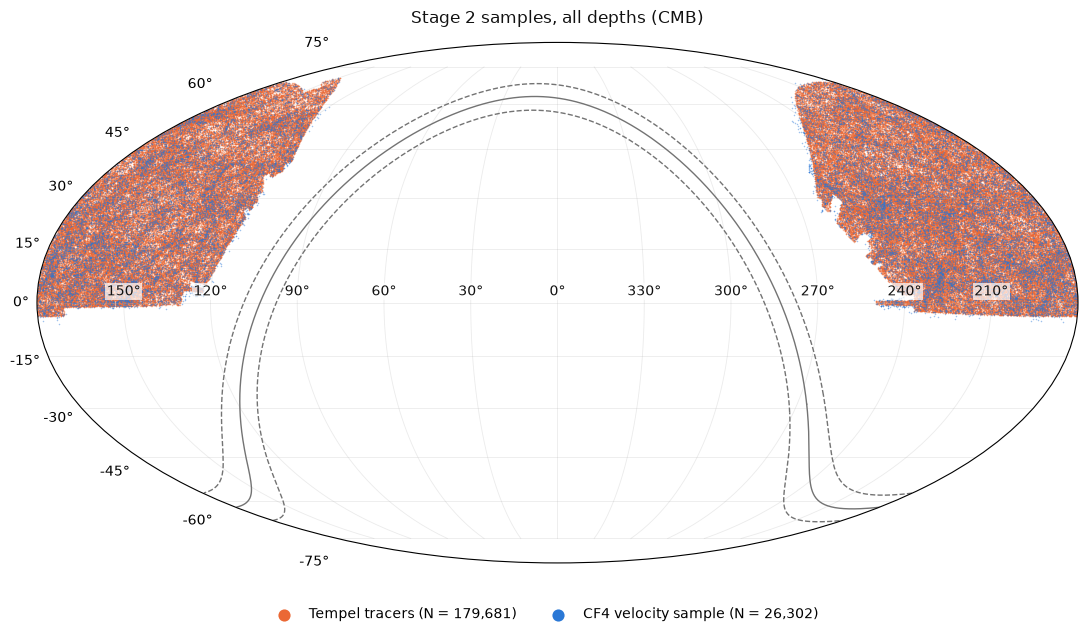

In [6]:
sky = [audit.tempel_tracer_sky_sample(tracers), audit.cf4_velocity_sky_sample(cf4)]
fig = audit.make_overlap_sky_map(sky, title="Stage 2 samples, all depths (CMB)",
                                 cz_max=config.velocity_cz_max)

**Reading it.** The CF4 points lie only on the Tempel cap, which satisfies the roadmap's *Done when*
condition. By construction, every CF4 group kept lies in an nside-32 pixel (3.4 deg², ~1.8° across) that
holds at least one Tempel galaxy. At the edge of the cap, such a pixel can reach up to one pixel width past
the last galaxy, so the footprint is slightly generous there. Stage 4 replaces it with the real angular
mask.

**n(cz) of the two samples.** Both now run to the survey limit, z = 0.1 (Tempel's deepest tracer is at
cz = 29,979 km/s; CF4's at 31,105). This is the cost of dropping the cut: a velocity center needs density
tracers out to its own cz + 64·100 km/s (64 h⁻¹ Mpc is the largest shell radius, rule 10), so every CF4
center beyond about 23,600 km/s (9,473 of the 26,302) has outer shells that run past the end of the Tempel field, and 53 CF4
centers lie deeper than any Tempel tracer at all. Those shells are incomplete, not empty of signal; the
randoms of Stage 4 have to account for them through the expected count n̄V_b.

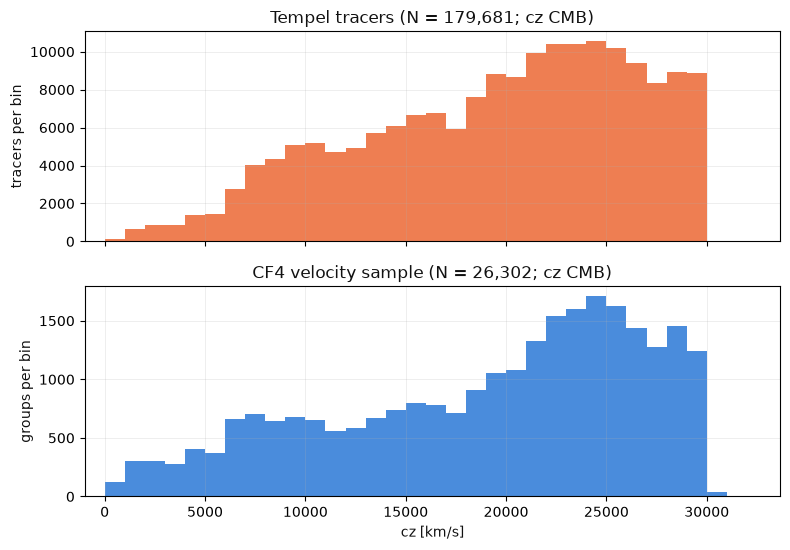

In [7]:
fig = audit.make_cz_histogram_figure(sky)

## 6 — 2MRS (M): the second density field

The advisor meeting of 2026-10-14 added the 2MRS K_s ≤ 11.75 galaxies, Nusser's own density field, as a
second density tracer M alongside Tempel. It pairs with its own CF4 velocity sample:

- **Density tracer:** `select_twomrs_tracers` keeps **every** 2MRS galaxy, one row each, keyed by `pgc`.
  2MRS is a galaxy catalog, not a group catalog, so there is nothing to collapse and no singleton trap.
  Its only velocity is heliocentric (`cz_hel`); the move to the CMB frame is Stage 3's.
- **Velocity tracer:** `select_cf4_velocities_in_twomrs` is the same CF4 selection as section 2 (no cz
  cut, the same u, undefined u dropped), with the analytic 2MRS mask in place of the SDSS pixels:
  |b| ≥ 5°, widened to 8° toward the bulge (l < 30° or l > 330°). Notebook 11 §9 showed every 2MRS
  galaxy honours it.

`counts_matrix` puts both pairs side by side. This is the roadmap's {T, M} × {CF4 groups} matrix; Phase B
adds one column block per CF4 source.

In [8]:
twomrs = load_twomrs_galaxies()
twomrs_tracers = select_twomrs_tracers(twomrs)
cf4_m = select_cf4_velocities_in_twomrs(velocities, cf4_groups, config)

dupes_m = twomrs_duplicate_test(twomrs_tracers, cf4_m)
display(dupes_m)
assert (dupes_m["duplicates"] == 0).all()

display(counts_matrix({"T (Tempel, SDSS footprint)": (tracers, cf4),
                       "M (2MRS, 2MRS mask)": (twomrs_tracers, cf4_m)}))
print(f"dropped for undefined u in M: pgc {cf4_m.undefined_pgc}")
velocities.table[velocities.table.pgc.isin(cf4_m.undefined_pgc)][
    ["pgc", "Vcmb", "Vls", "fV", "DMzp", "eDM", "Vpds", "Vpwf", "Vpec"]]

,rows,unique_keys,duplicates
key,,,
"2MRS galaxies, by pgc",43526,43526,0
"CF4 groups, by pgc",38003,38003,0


,density_tracers,cf4_in_footprint,cf4_undefined_u,cf4_velocity_sample,cf4_calibrators
pair,,,,,
"T (Tempel, SDSS footprint)",179681,26303,1,26302,81
"M (2MRS, 2MRS mask)",43526,38007,4,38003,220


dropped for undefined u in M: pgc (8484, 39346, 69468, 3097727)


,pgc,Vcmb,Vls,fV,DMzp,eDM,Vpds,Vpwf,Vpec
1249,8484,0,438,0,28.12,0.0,-314,0,-268
6499,39346,0,94,0,28.17,0.0,-321,0,-311
11447,69468,0,332,0,26.70,0.0,-163,0,-145
30259,3097727,0,335,0,28.11,0.0,-312,0,-277


**Reading the matrix.**

- **M density tracers: 43,526**, every galaxy in the file. The roadmap's *Expect* for M was "far more CF4
  centers than the 4,481 inside SDSS"; with no cz cut the comparison is 38,003 against 26,302.
- **CF4 inside the 2MRS mask: 38,007 of 38,057.** Only 50 CF4 groups sit in the Galactic-plane strip.
  At cz < 10,000 the same selection gives 12,077, the count notebook 11 §10 reported (checked in
  `tests/test_real_catalogs.py`).
- **4 groups dropped for undefined u**, all of the kind section 2 found: calibrators (eDM = 0) at
  `Vcmb` = 0, where `fV` = 0 and the file's `Vpwf` is a filler 0. pgc 39346 is the one the T sample also
  drops; the other three lie outside SDSS. None is filled (rule 5).
- **220 calibrators** (σ_u not given) are kept, against 81 in T.

The 2MRS mask covers the whole SDSS cap (the CF4 T sample sits at |b| ≥ 17.6°), so every T velocity
center should also be an M velocity center. The check:

In [9]:
t_pgc, m_pgc = set(cf4.table["pgc"]), set(cf4_m.table["pgc"])
print(f"T centers also in M: {len(t_pgc & m_pgc):,} of {len(t_pgc):,};  M only: {len(m_pgc - t_pgc):,}")
assert t_pgc <= m_pgc

T centers also in M: 26,302 of 26,302;  M only: 11,701


### Sky plot of the M pair, all depths

2MRS tracers first (bottom), CF4 velocity tracers on top. The solid line is the Galactic plane; the dashed
lines are the mask edge at |b| = 5° (the wider 8° cut toward the bulge is not drawn). **What right looks
like:** both samples cover the whole sky apart from the strip between the dashed lines, and no CF4 point
falls inside that strip. The southern sky, absent from T, now carries velocity centers: this is where the
6dFGS Fundamental Plane groups live (Stage 8B).

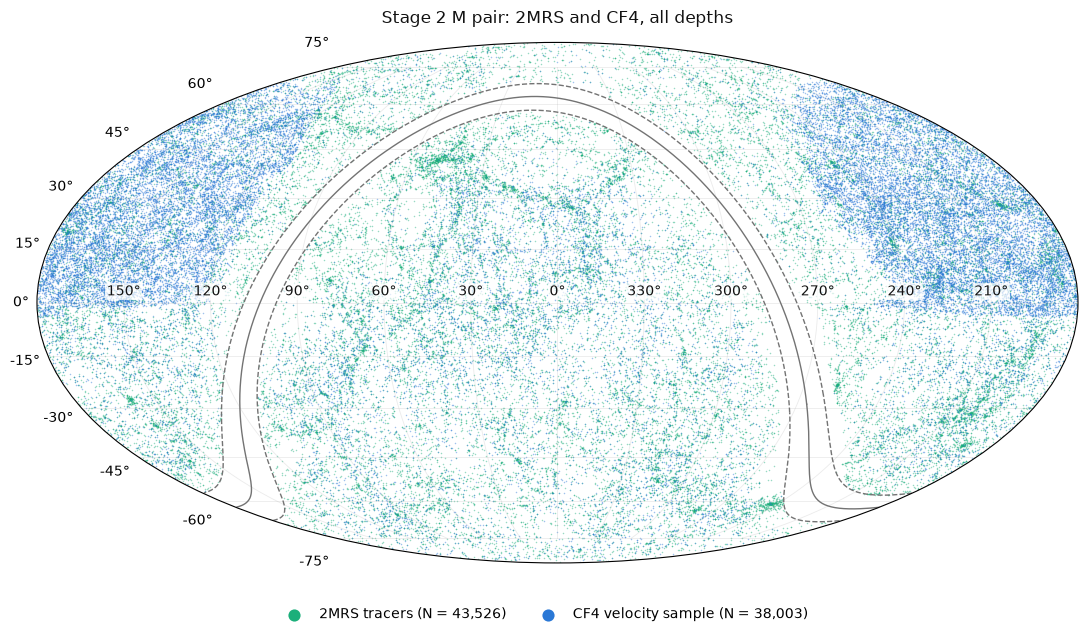

In [10]:
sky_m = [audit.twomrs_tracer_sky_sample(twomrs_tracers), audit.cf4_velocity_sky_sample(cf4_m)]
fig = audit.make_overlap_sky_map(sky_m, title="Stage 2 M pair: 2MRS and CF4, all depths")

**n(cz) of the M pair.** 2MRS cz is heliocentric, CF4 is CMB-frame: the two differ by up to ~370 km/s
over the sky, which is invisible at this bin width.

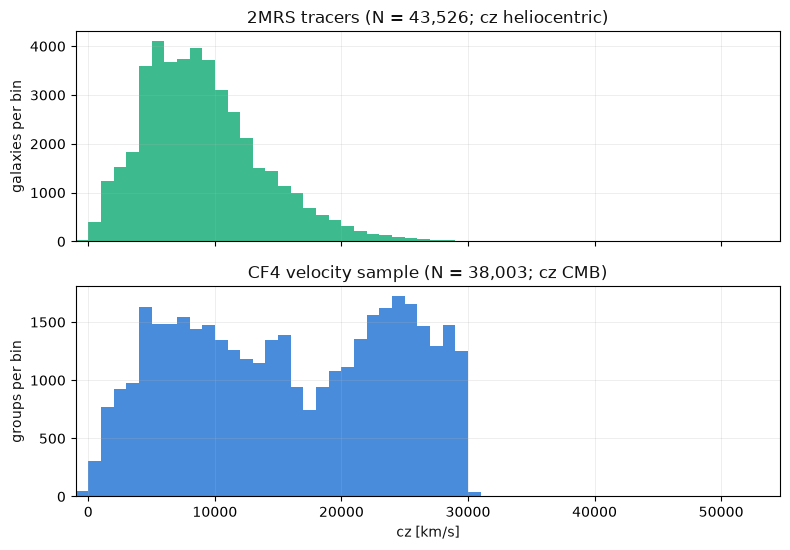

In [11]:
fig = audit.make_cz_histogram_figure(sky_m)

**Reading it.** The two samples have very different depths. 2MRS is a bright, shallow survey: its median
galaxy is at cz ≈ 8,400 km/s, and 97.5% of it lies below 20,000 km/s. The CF4 groups in its mask have a
median of ≈ 15,500 km/s, and 38% of them lie beyond 20,000 km/s, where 2MRS has only ~1,100 galaxies
over the whole sky. Without a cz cut, most M velocity centers sit where the density field is very sparse,
and Nusser's 1/φ(r) weights (Stage 4) become large and noisy there. This is the case for reinstating a
depth cut for the M pair at least, once the estimator is run; the cut is a single `SampleConfig` field.

## Done when — status

| Stage 2 *Done when* | Status |
| --- | --- |
| Duplicate test passes (one row per group and per CF4 object) | **passes** (section 3; also a pytest gate) |
| Counts match | **match** at all depths; the cz < 10,000 variant reproduces too, apart from 6,360 / 15,272 against the roadmap's 6,367 / 15,278, explained in section 4 |
| Sky plot shows CF4 centers inside the Tempel footprint | **yes** (section 5) |
| **[2026-10-14]** the same for the 2MRS density field (M), counts matrix filled | **done** (section 6): duplicate test passes, matrix filled, sky plot shows CF4 only outside the plane strip |
| **[2026-10-14]** Phase B per-source velocity samples | **blocked**: the CF4 individual-galaxy table is not in `data/` |

Both density fields of Phase A are built. Phase B waits for the CF4 individual-galaxy table.
